Explorty Data Analysis(EDA)
- 1 Dataset structure :- 
   shape, columns, dtypes, head, duplicate rows
- 2 Data quality :- 
   missing vlaues, invalid ranges, unique values, category consistency
- 3 Target analysis :- 
   y , histogram , mean, median , spread , outliers
- 4 Numerical relationships
- 5 Categorical Comparison
- 6 Multicollinearity
- 7 Leakage check
- 8 Model readiness
    Train/test split, preprocessing pipeline and  baseline ANN


In [1]:
import pandas as pd
import numpy  as np

In [2]:
df = pd.read_csv('../data/bank-full.csv',sep=";")

In [3]:
# pd.set_option('display.max_rows', None)
# pd.set_option('display.max_columns', None)
# pd.set_option('display.max_colwidth', None)
# pd.set_option('display.width', 1000)

###  Data Structure

In [4]:
df.shape

(45211, 17)

In [5]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')

In [6]:
df.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [7]:
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [8]:
df.duplicated().sum()

np.int64(0)

#### Observation:
- The Dataset not contain duplicated records

### Data quality

#### Missing Values Checking 

In [9]:
print(df.isnull().sum())

missing_percent = (df.isnull().sum() / len(df)) * 100

print(missing_percent.sort_values(ascending=False))

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
age          0.0
job          0.0
marital      0.0
education    0.0
default      0.0
balance      0.0
housing      0.0
loan         0.0
contact      0.0
day          0.0
month        0.0
duration     0.0
campaign     0.0
pdays        0.0
previous     0.0
poutcome     0.0
y            0.0
dtype: float64


### Checking Invalid Range

In [10]:
df.head(3)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no


In [11]:
print(df[(df['age'] < 0)  | (df['age'] > 100)])
print(df[(df['day'] < 1)  | (df['day'] > 31)])
df[df["duration"] < 0]
df[df["campaign"] < 1]
df[df["previous"] < 0]
df[~df["day"].between(1, 31)]

Empty DataFrame
Columns: [age, job, marital, education, default, balance, housing, loan, contact, day, month, duration, campaign, pdays, previous, poutcome, y]
Index: []
Empty DataFrame
Columns: [age, job, marital, education, default, balance, housing, loan, contact, day, month, duration, campaign, pdays, previous, poutcome, y]
Index: []


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y


In [12]:
df.head(2)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no


In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [33]:

quality_report = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique(dropna=False),
    'Duplicate Count': [
        df[col].duplicated().sum()
        for col in df.columns
    ]
})

quality_report.sort_values(
    by='Missing %',
    ascending=False
)

,Data Type,Missing Count,Missing %,Unique Values,Duplicate Count
age,int64,0,0.0,77,45134
job,str,0,0.0,12,45199
marital,str,0,0.0,3,45208
education,str,0,0.0,4,45207
default,str,0,0.0,2,45209
balance,int64,0,0.0,7168,38043
housing,str,0,0.0,2,45209
loan,str,0,0.0,2,45209
contact,str,0,0.0,3,45208
day,int64,0,0.0,31,45180


In [14]:
print(df.nunique(dropna=False).sort_values())

housing         2
loan            2
default         2
y               2
contact         3
marital         3
poutcome        4
education       4
month          12
job            12
day            31
previous       41
campaign       48
age            77
pdays         559
duration     1573
balance      7168
dtype: int64


#### Categorical Consistency

In [15]:
categorical_columns = df.select_dtypes(include=['object','str']).columns

for col in categorical_columns:
    print("Columns Name:-",col)
    print(df[col].dropna().unique())
    print()

Columns Name:- job
<ArrowStringArray>
[   'management',    'technician',  'entrepreneur',   'blue-collar',
       'unknown',       'retired',        'admin.',      'services',
 'self-employed',    'unemployed',     'housemaid',       'student']
Length: 12, dtype: str

Columns Name:- marital
<ArrowStringArray>
['married', 'single', 'divorced']
Length: 3, dtype: str

Columns Name:- education
<ArrowStringArray>
['tertiary', 'secondary', 'unknown', 'primary']
Length: 4, dtype: str

Columns Name:- default
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

Columns Name:- housing
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

Columns Name:- loan
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

Columns Name:- contact
<ArrowStringArray>
['unknown', 'cellular', 'telephone']
Length: 3, dtype: str

Columns Name:- month
<ArrowStringArray>
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb', 'mar', 'apr',
 'sep']
Length: 12, dtype: str

Columns Name:- poutcome
<ArrowS

#### Observation:
- The Dataset not contain Inconsistent values|
- The Dataset not contain Invalid Range but in the Balance and pdays columns have Negative values


#### Target  Analysis

In [16]:
df.head(2)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no


In [17]:
Target_map = {
    "no" : 0,
    "yes" : 1
}
df['y']  = df['y'].map(Target_map)

In [18]:
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,1
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,1
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,1
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,0
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,0


In [19]:
df.rename(columns={'y': 'Target'}, inplace=True)   

In [20]:
df['Target'].value_counts(normalize=True) * 100

Target
0    88.30152
1    11.69848
Name: proportion, dtype: float64

### Observation of Target Columns
- The Target is imbalanced because  target no is 91% and the target yes 10

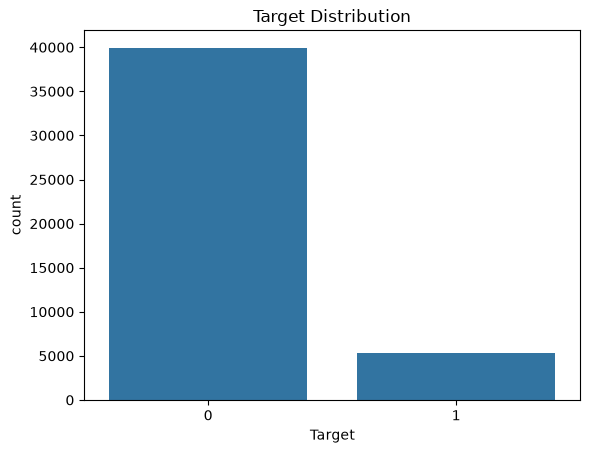

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x = 'Target')
plt.title("Target Distribution")
plt.show()

#### Target vs Categorical Columns

In [22]:
df.head(3)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,Target
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0


In [23]:
Target_and_job = pd.crosstab(
    df['job'],
    df['Target'],
    normalize='index'
) * 100

print(Target_and_job.columns.tolist())
print(Target_and_job.head())


[0, 1]
Target                0          1
job                               
admin.        87.797331  12.202669
blue-collar   92.725031   7.274969
entrepreneur  91.728312   8.271688
housemaid     91.209677   8.790323
management    86.244449  13.755551


**Observation:** Students have the highest term deposit subscription rate (28.68%), followed by retired customers (22.79%). This suggests that students and retired customers are more likely to subscribe to a term deposit compared to other job categories in this dataset.

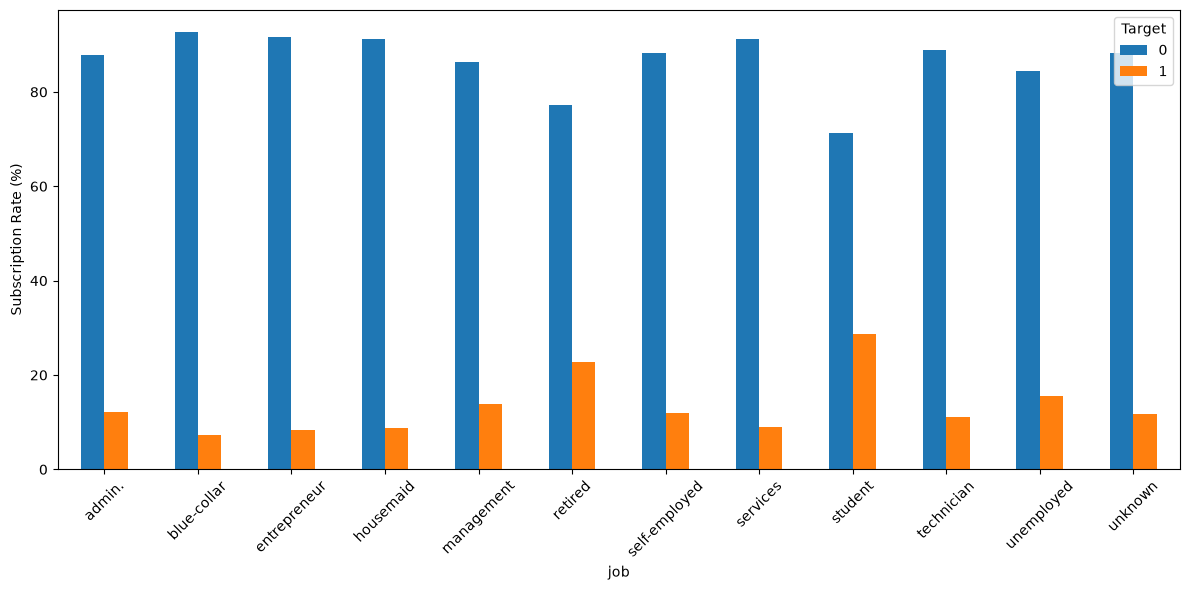

In [24]:
Target_and_job.plot(kind='bar', figsize=(12, 6))
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
categorical_cols = df.select_dtypes(
    include="object"
).columns.drop("Target", errors="ignore")

for col in categorical_cols:
    print(f"\nTarget Analysis: {col}")

    result = pd.crosstab(
        df[col],
        df["Target"],
        normalize="index"
    ) * 100

    print(result)
    print("--------------------------------------")


Target Analysis: job
Target                 0          1
job                                
admin.         87.797331  12.202669
blue-collar    92.725031   7.274969
entrepreneur   91.728312   8.271688
housemaid      91.209677   8.790323
management     86.244449  13.755551
retired        77.208481  22.791519
self-employed  88.157061  11.842939
services       91.116996   8.883004
student        71.321962  28.678038
technician     88.943004  11.056996
unemployed     84.497314  15.502686
unknown        88.194444  11.805556
--------------------------------------

Target Analysis: marital
Target            0          1
marital                       
divorced  88.054542  11.945458
married   89.876534  10.123466
single    85.050821  14.949179
--------------------------------------

Target Analysis: education
Target             0          1
education                      
primary    91.373522   8.626478
secondary  89.440565  10.559435
tertiary   84.993610  15.006390
unknown    86.429725  13.57

C:\Users\mdsal\AppData\Local\Temp\ipykernel_21112\684447297.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


### 1. Job
**Observation:** Students have the highest term deposit subscription rate (28.68%), followed by retired customers (22.79%) and unemployed customers (15.50%). Blue-collar workers have the lowest subscription rate (7.27%).

### 2. Marital Status
**Observation:** Single customers have the highest subscription rate (14.95%), followed by divorced customers (11.95%). Married customers have the lowest rate (10.12%).

### 3. Education
**Observation:** Customers with tertiary education have the highest subscription rate (15.01%), followed by those with secondary education (10.56%). Customers with primary education have the lowest rate (8.63%).

### 4. Default
**Observation:** Customers without credit in default have a subscription rate of 11.80%, compared with 6.38% for customers with credit in default. Customers without credit in default show a higher subscription rate.

### 5. Housing Loan
**Observation:** Customers without a housing loan have a higher subscription rate (16.70%) than customers with a housing loan (7.70%).

### 6. Personal Loan
**Observation:** Customers without a personal loan have a higher subscription rate (12.66%) than customers with a personal loan (6.68%).

### 7. Contact
**Observation:** Customers contacted through cellular communication have a subscription rate of 14.92%, followed by telephone contacts at 13.42%. Customers with an unknown contact method have the lowest rate (4.07%).

### 8. Month
**Observation:** March has the highest subscription rate (51.99%), followed by December (46.73%), October (43.77%), and September (46.46%). May has the lowest subscription rate (6.72%). Subscription rates vary considerably across months.

### 9. Previous Campaign Outcome (`poutcome`)
**Observation:** Customers whose previous campaign outcome was successful have the highest subscription rate (64.73%). Customers with an outcome of `other` have a rate of 16.68%, followed by `failure` at 12.61%. Customers with an unknown previous outcome have the lowest rate (9.16%).

### Overall Conclusion
**Observation:** Job, marital status, education, credit default, housing loans, personal loans, contact method, month, and previous campaign outcome show different subscription rates across their categories. Previous campaign success, contact month, and job category display particularly noticeable differences in this dataset. These features may be useful for predicting term deposit subscriptions, subject to further statistical analysis and model evaluation.

In [26]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# categorical_cols = df.select_dtypes(
#     include=["object", "str", "category"]
# ).columns.drop("Target", errors="ignore")

# for col in categorical_cols:
#     plt.figure(figsize=(10, 5))

#     sns.countplot(data=df, x=col, hue="Target")

#     plt.title(f"{col} vs Target")
#     plt.xlabel(col)
#     plt.ylabel("Customer Count")
#     plt.xticks(rotation=45)
#     plt.tight_layout()
#     plt.show()

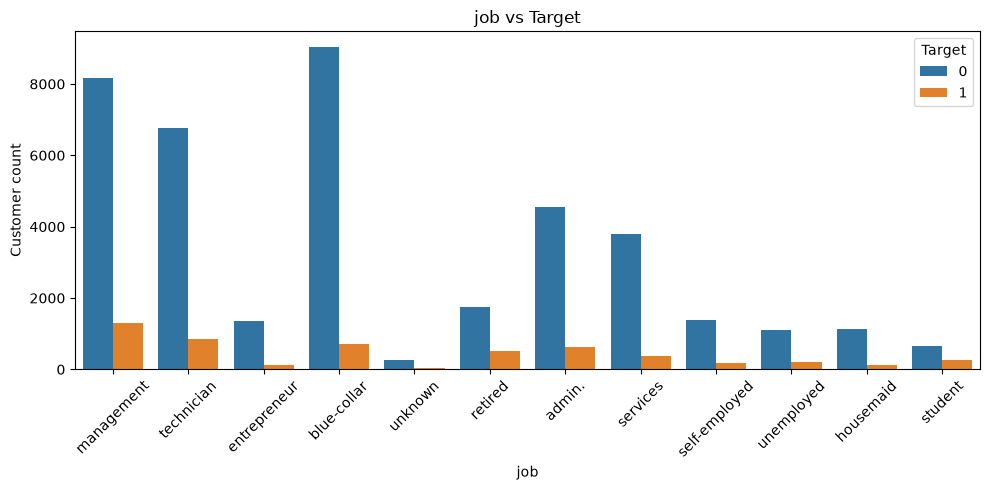

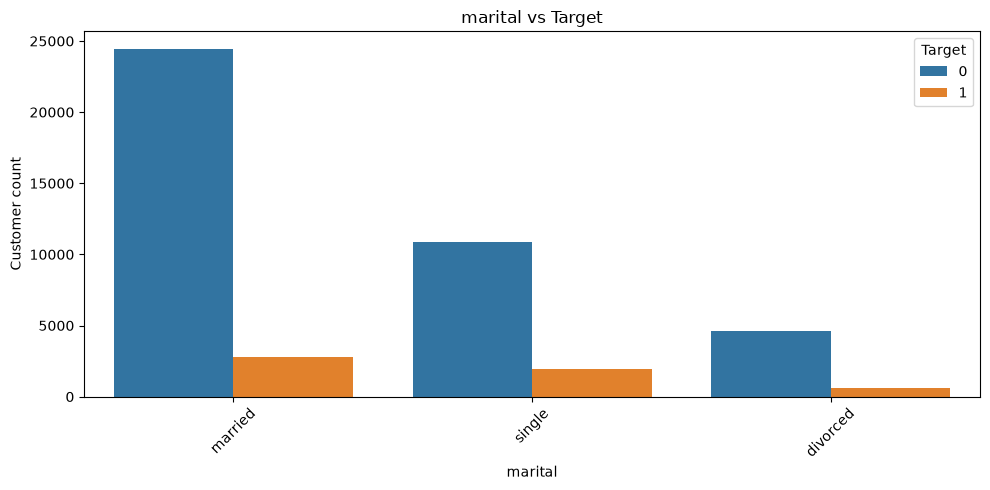

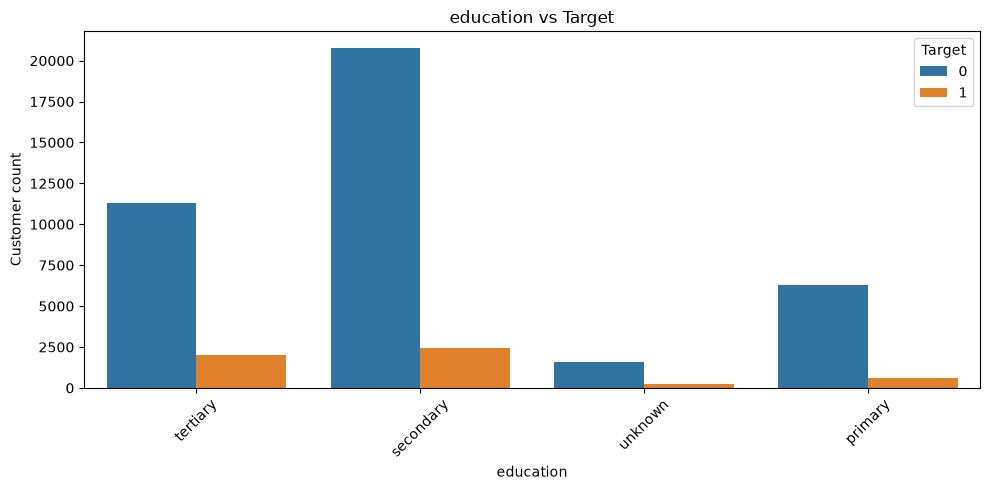

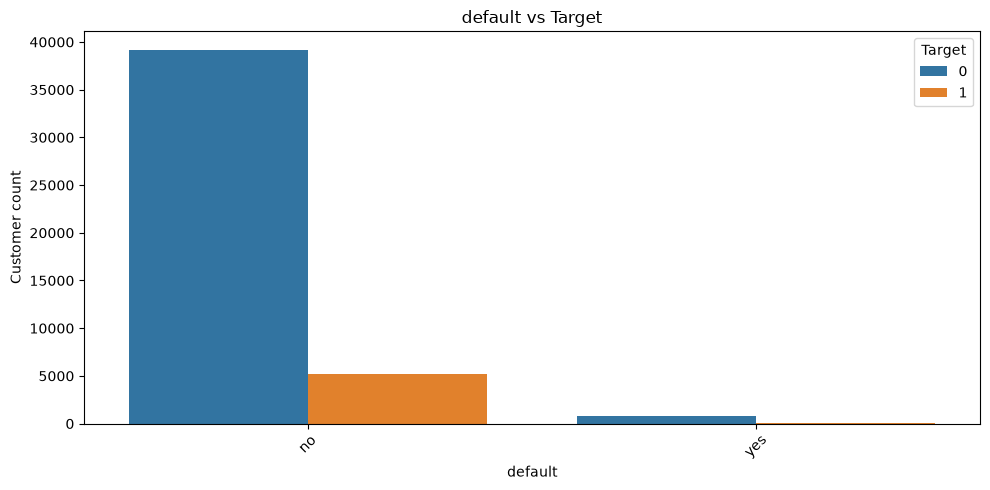

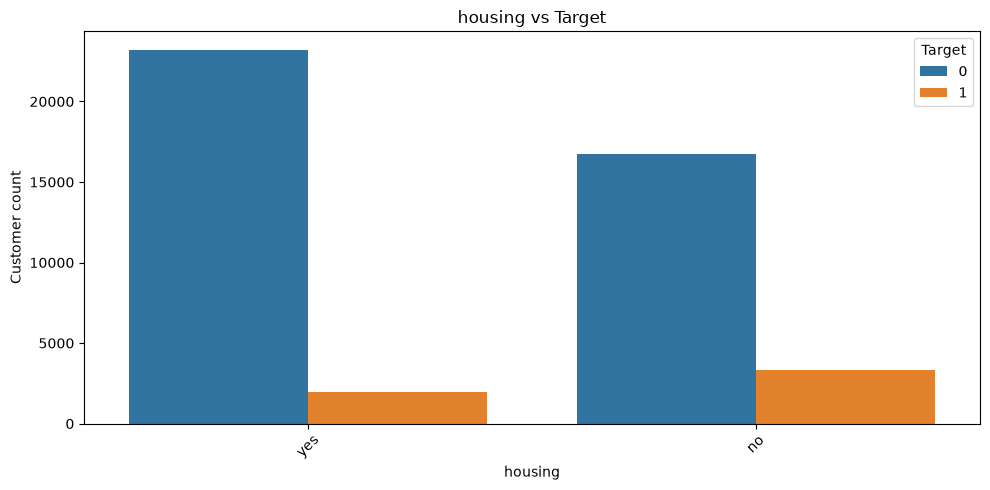

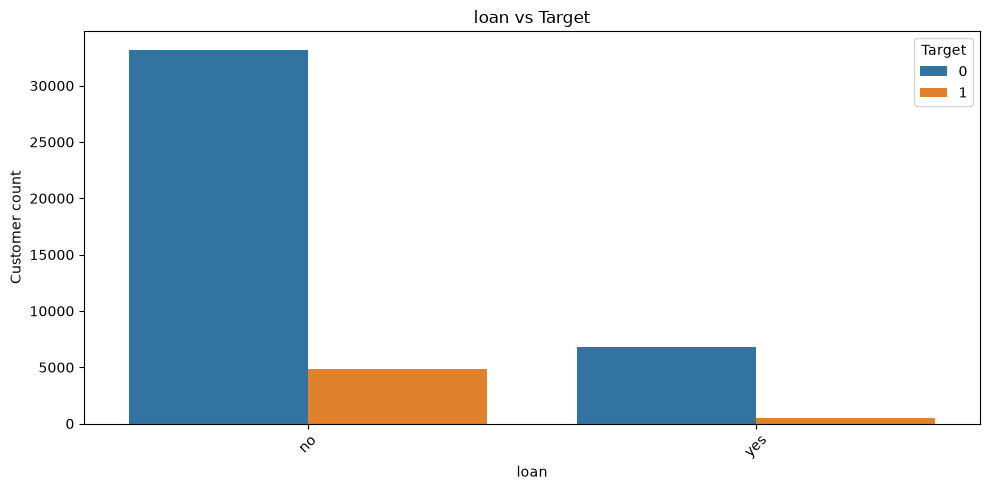

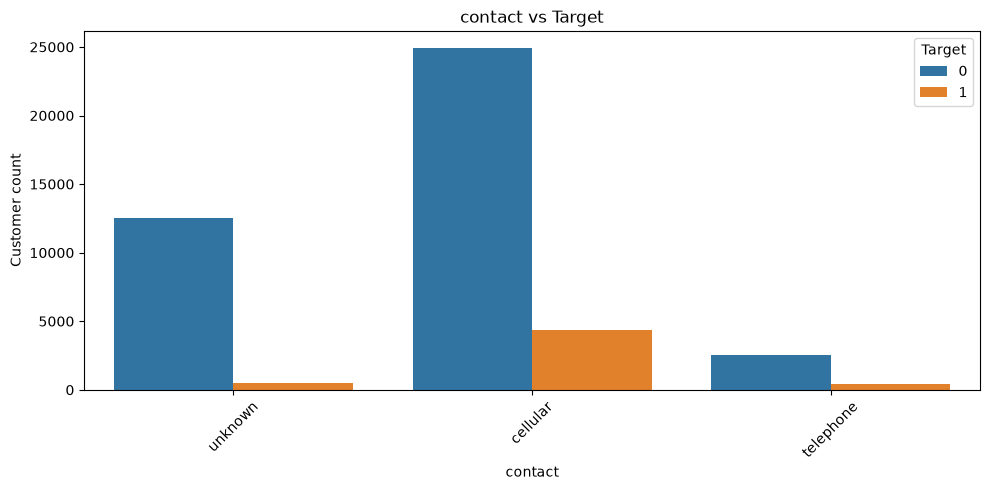

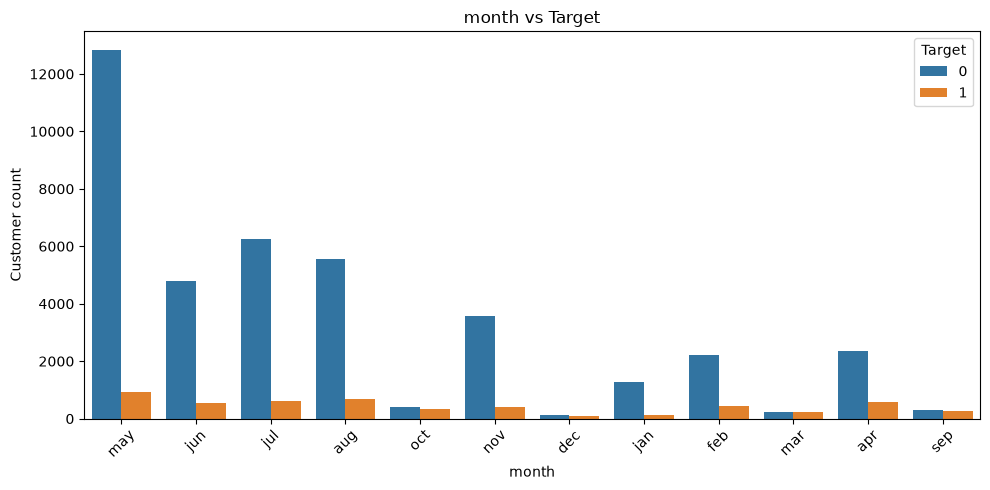

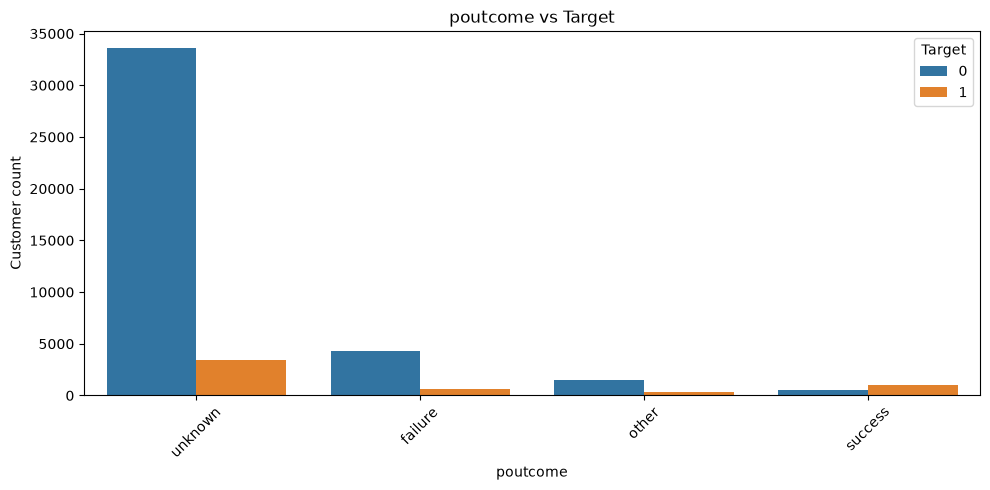

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
categorical_cols = df.select_dtypes(
    include=['object',"str","category"]
).columns.drop("Target",errors="ignore")

for col in categorical_cols:
    plt.figure(figsize=(10,5))
    
    sns.countplot(data=df, x=col, hue="Target")
    
    plt.title(f"{col} vs Target")
    plt.xlabel(col)
    plt.ylabel("Customer count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

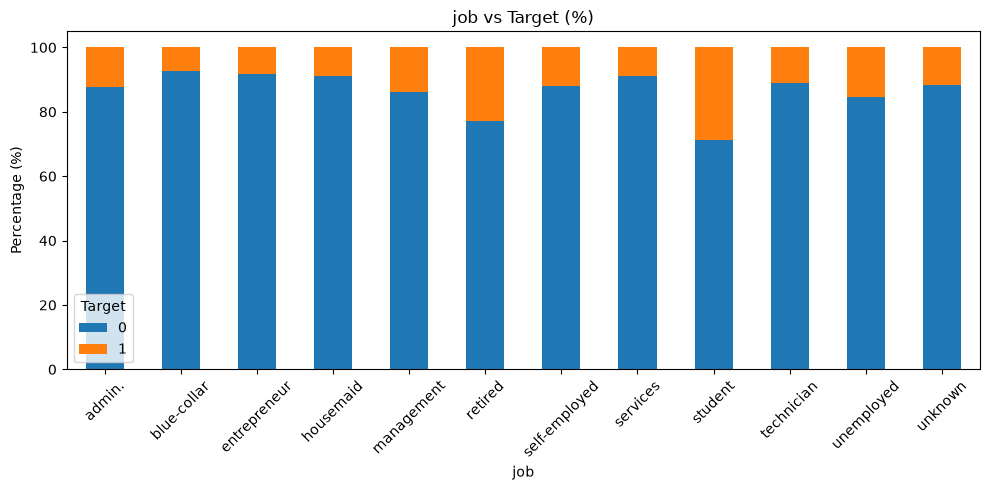

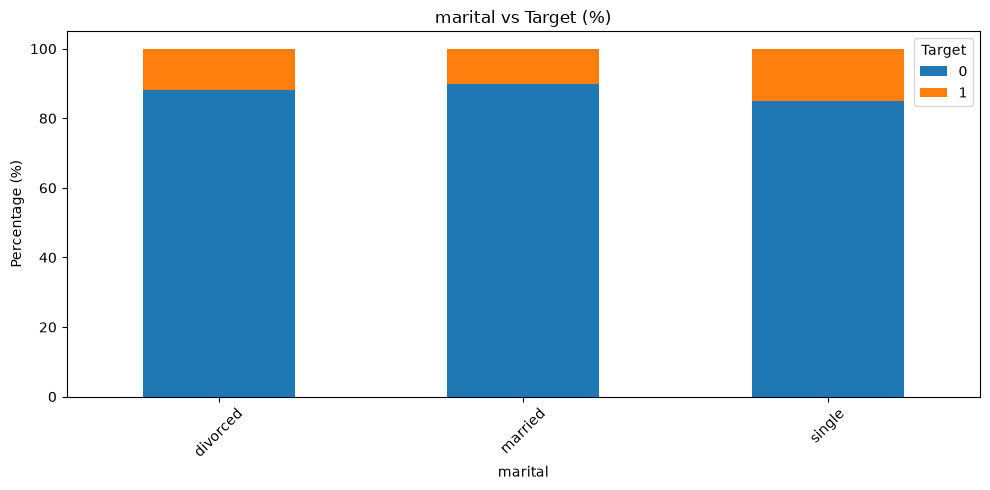

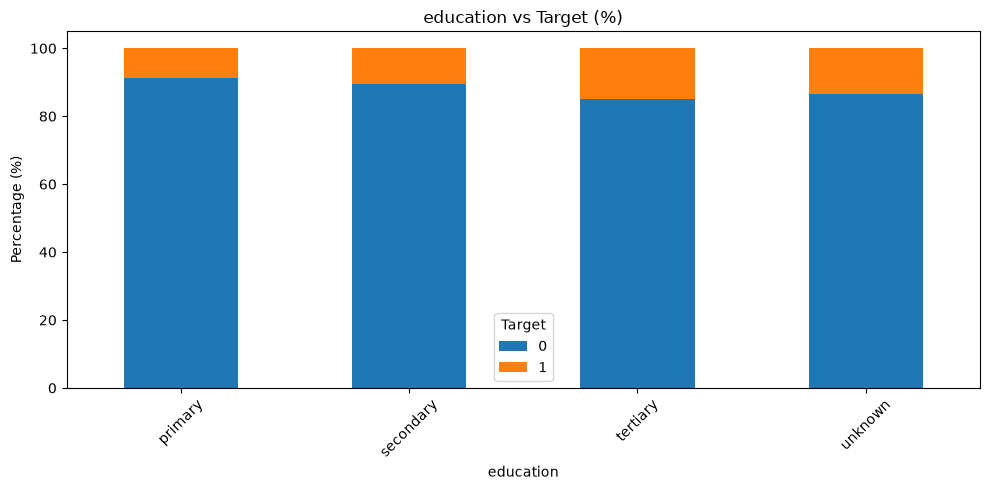

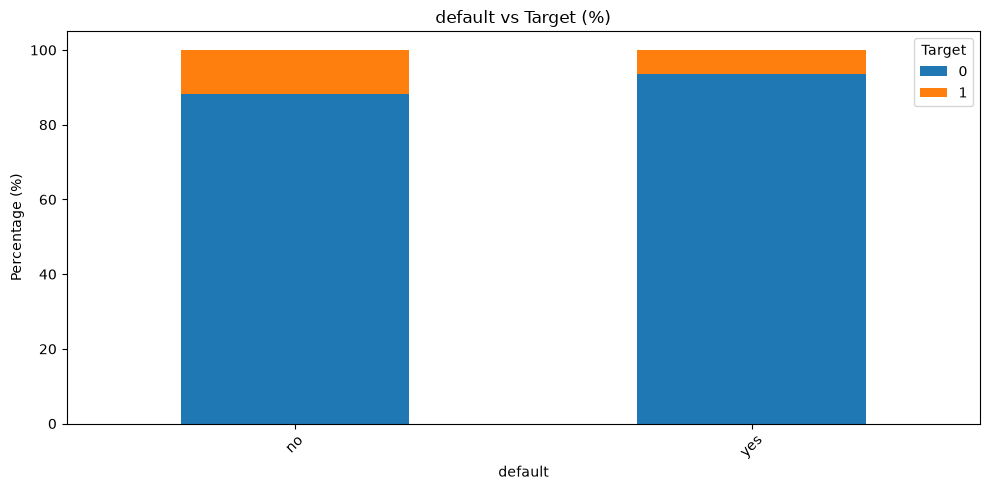

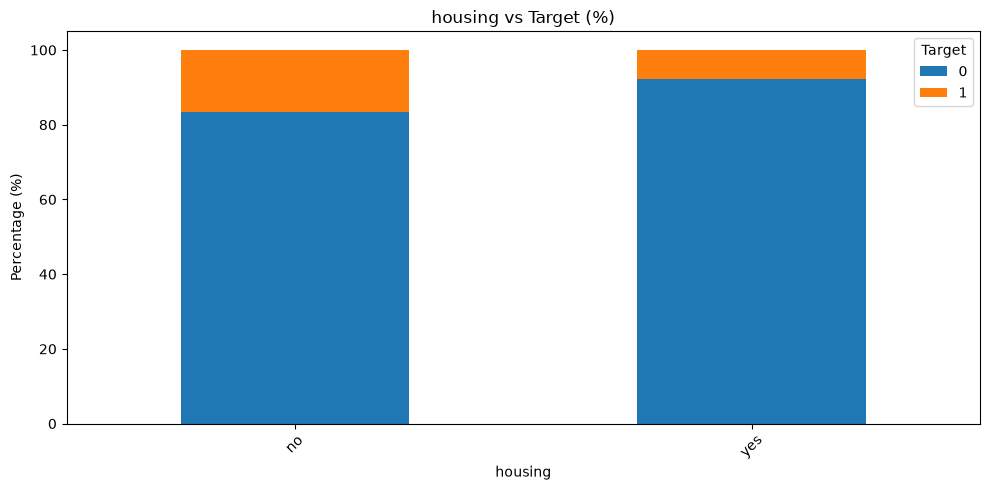

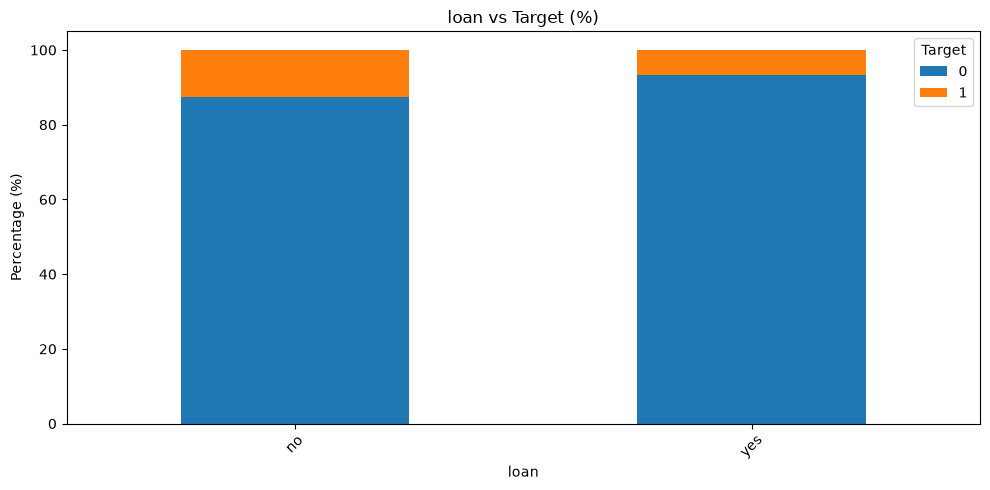

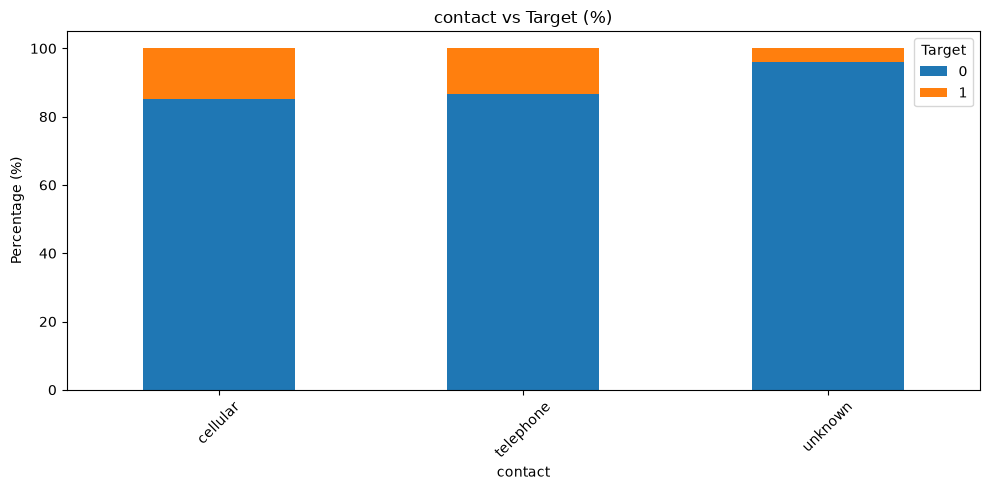

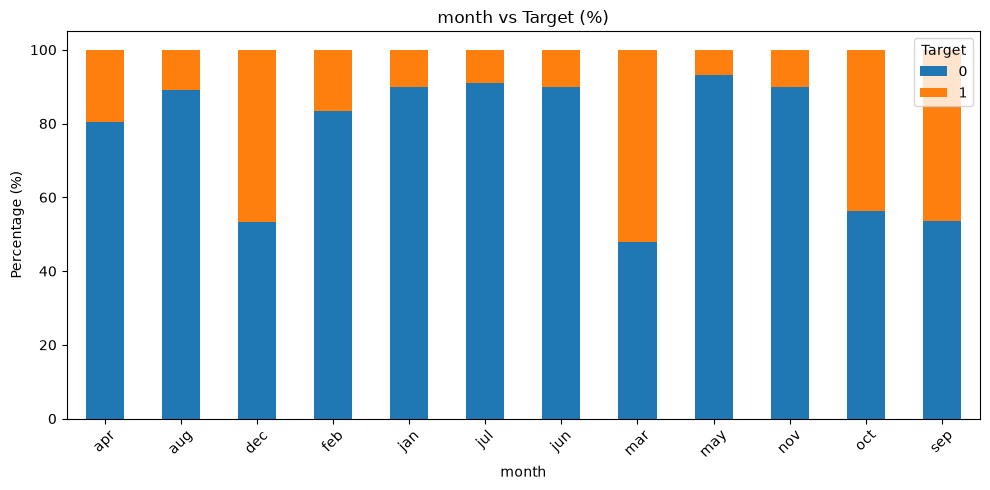

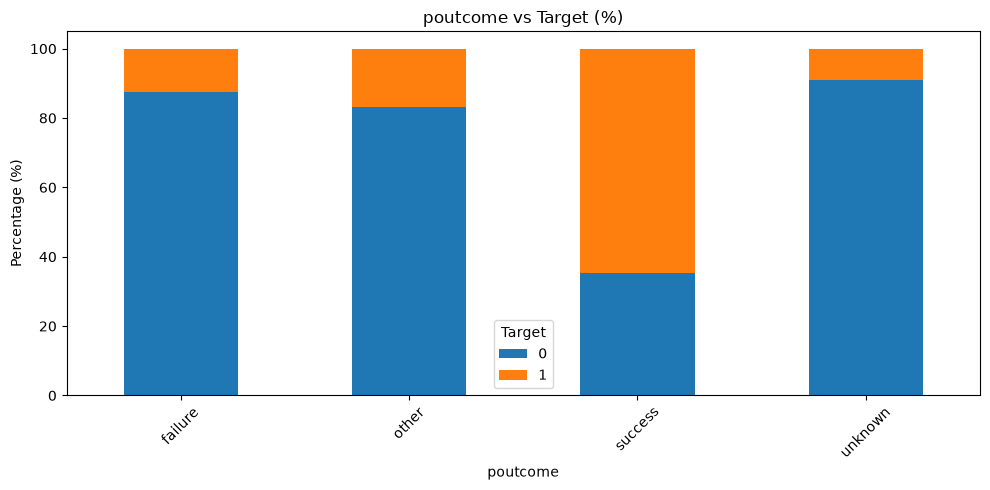

In [28]:
for col in categorical_cols:
    target_rate = pd.crosstab(
        df[col],
        df["Target"],
        normalize="index"
    ) * 100

    target_rate.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )

    plt.title(f"{col} vs Target (%)")
    plt.xlabel(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=45)
    plt.legend(title="Target")
    plt.tight_layout()
    plt.show()

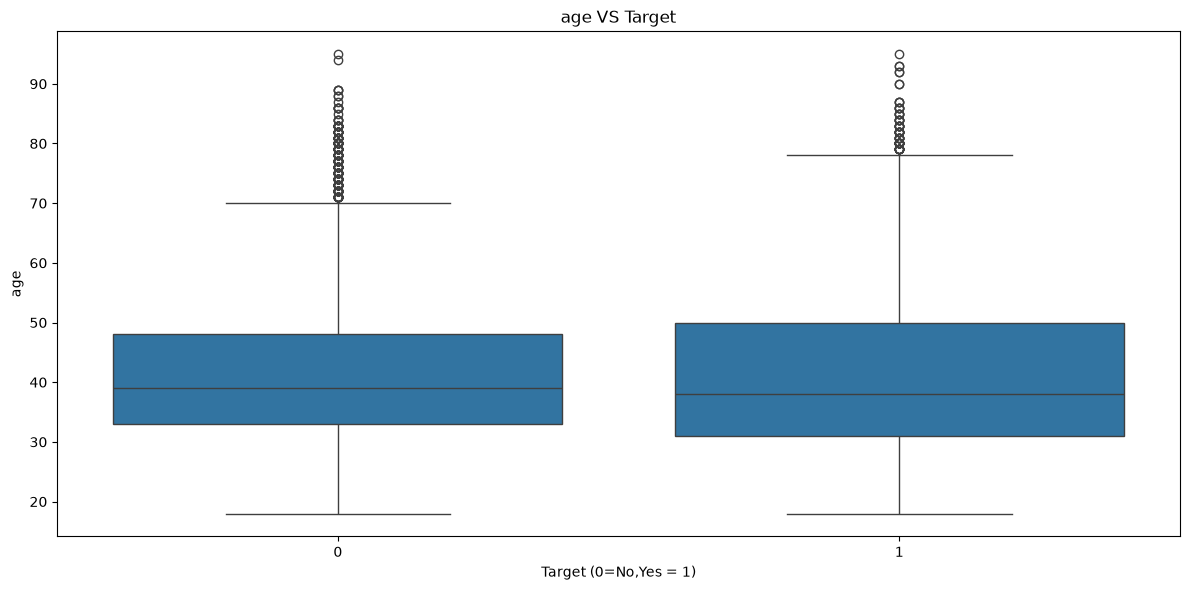

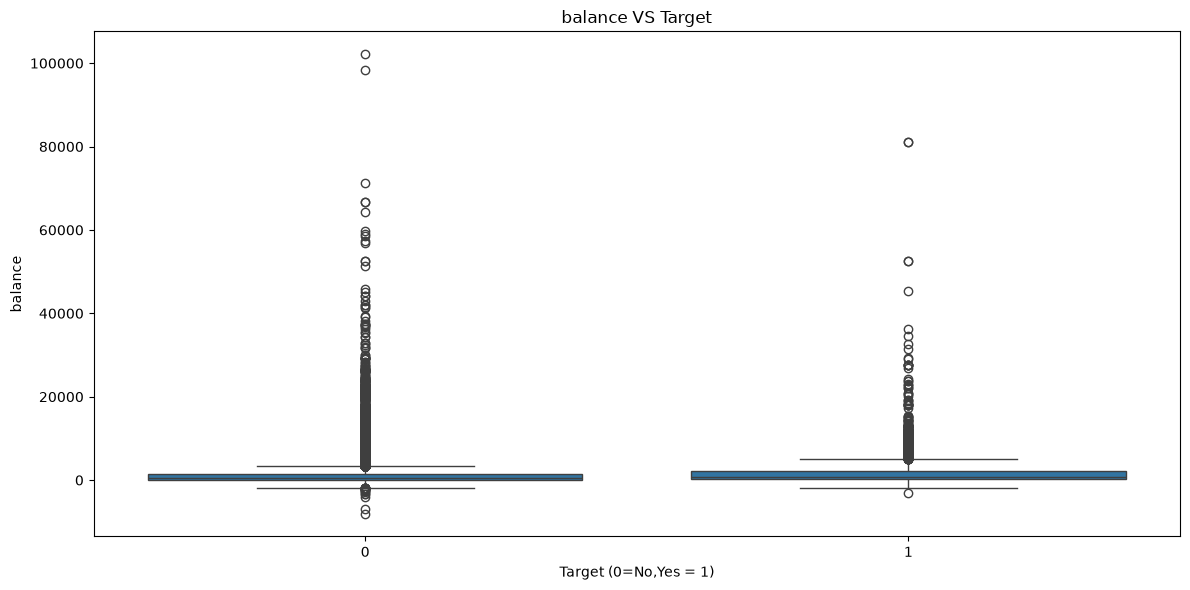

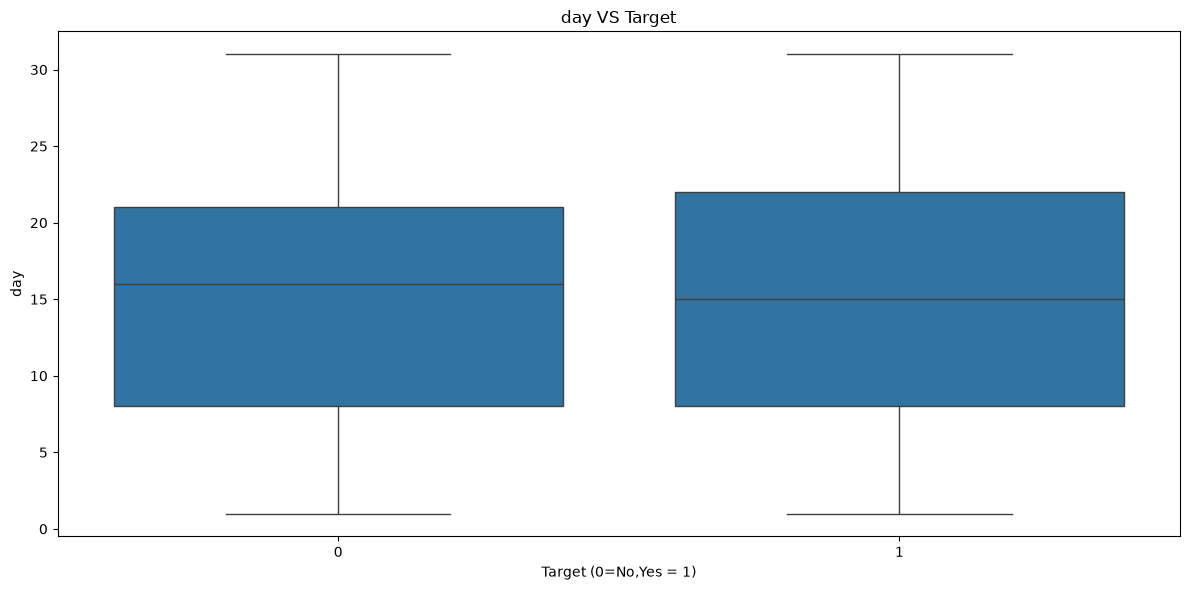

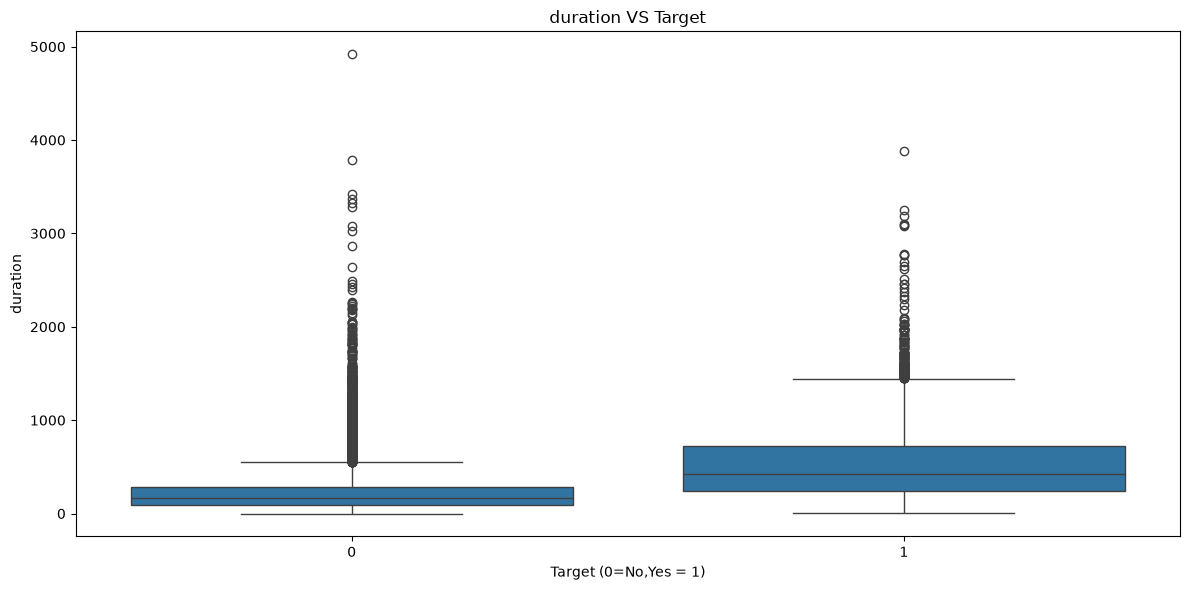

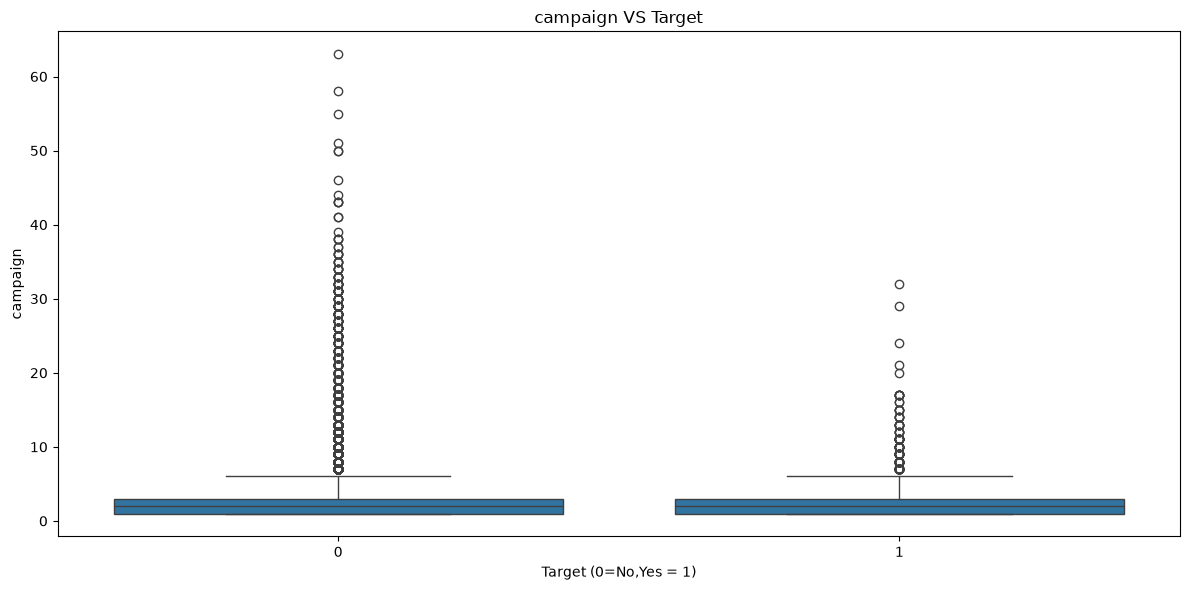

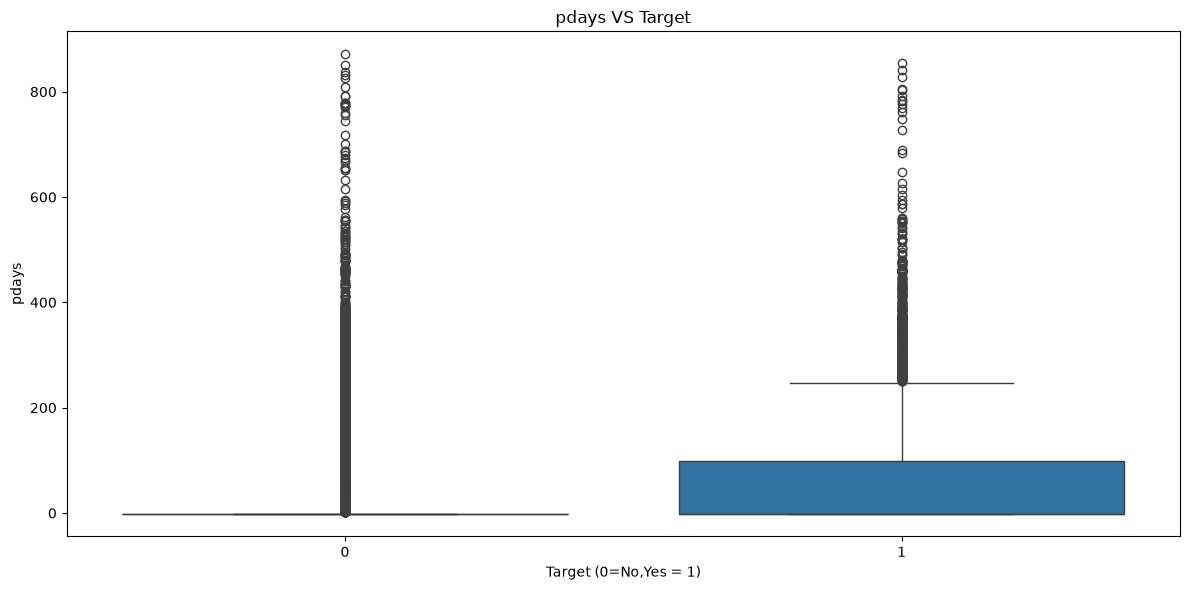

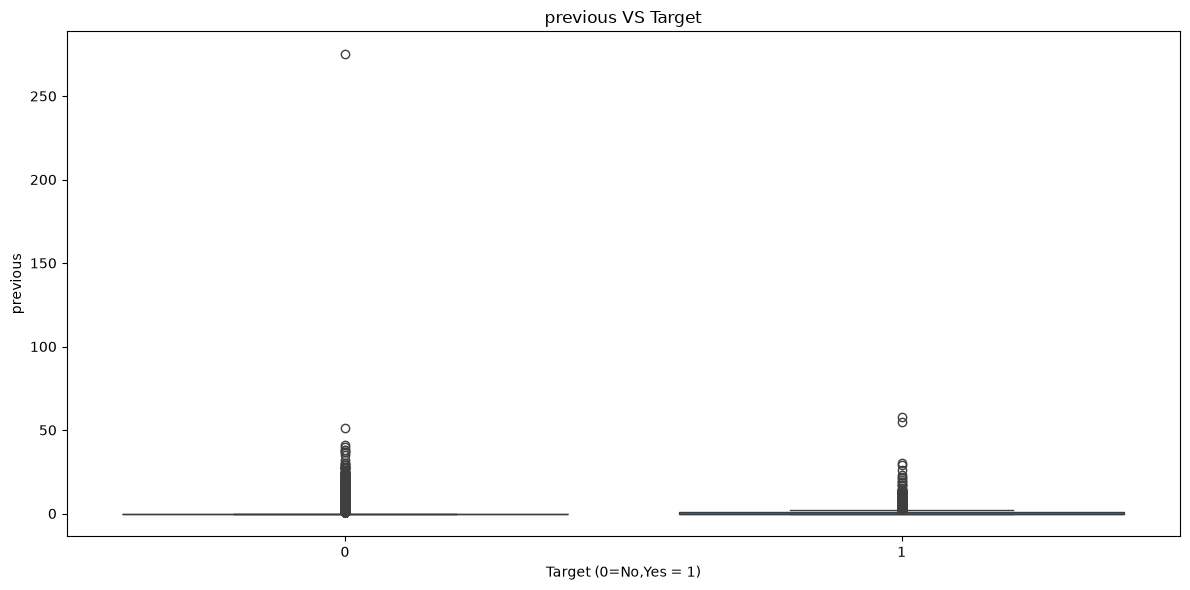

In [29]:
numerical_columns = df.select_dtypes(
    include="number"
).columns.drop("Target", errors="ignore")

for col in numerical_columns:
    plt.figure(figsize=(12, 6))
    
    sns.boxplot(data=df, x="Target", y=col)
    
    plt.title(f"{col} VS Target")
    plt.xlabel("Target (0=No,Yes = 1)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

In [30]:
for col in numerical_columns:
    print(f"\n{col} vs Target")
    
    print(
        df.groupby("Target")[col].agg(
            ["mean", "median", "std"]
        )
    )


age vs Target
             mean  median        std
Target                              
0       40.838986    39.0  10.172662
1       41.670070    38.0  13.497781

balance vs Target
               mean  median          std
Target                                  
0       1303.714969   417.0  2974.195473
1       1804.267915   733.0  3501.104777

day vs Target
             mean  median       std
Target                             
0       15.892290    16.0  8.294728
1       15.158253    15.0  8.501875

duration vs Target
              mean  median         std
Target                                
0       221.182806   164.0  207.383237
1       537.294574   426.0  392.525262

campaign vs Target
            mean  median       std
Target                            
0       2.846350     2.0  3.212767
1       2.141047     2.0  1.921826

pdays vs Target
             mean  median         std
Target                               
0       36.421372    -1.0   96.757135
1       68.702968    -1.0  1

**Statistical Test Observation — Example**

The statistical test indicates whether there is sufficient evidence of a difference in the numerical feature between customers who subscribed to a term deposit and those who did not. If the p-value is below the chosen significance level (commonly 0.05), the difference is considered statistically significant. Otherwise, there is insufficient evidence to conclude that a difference exists.

The final conclusion should be based on the actual test results, not only on differences in means or medians.

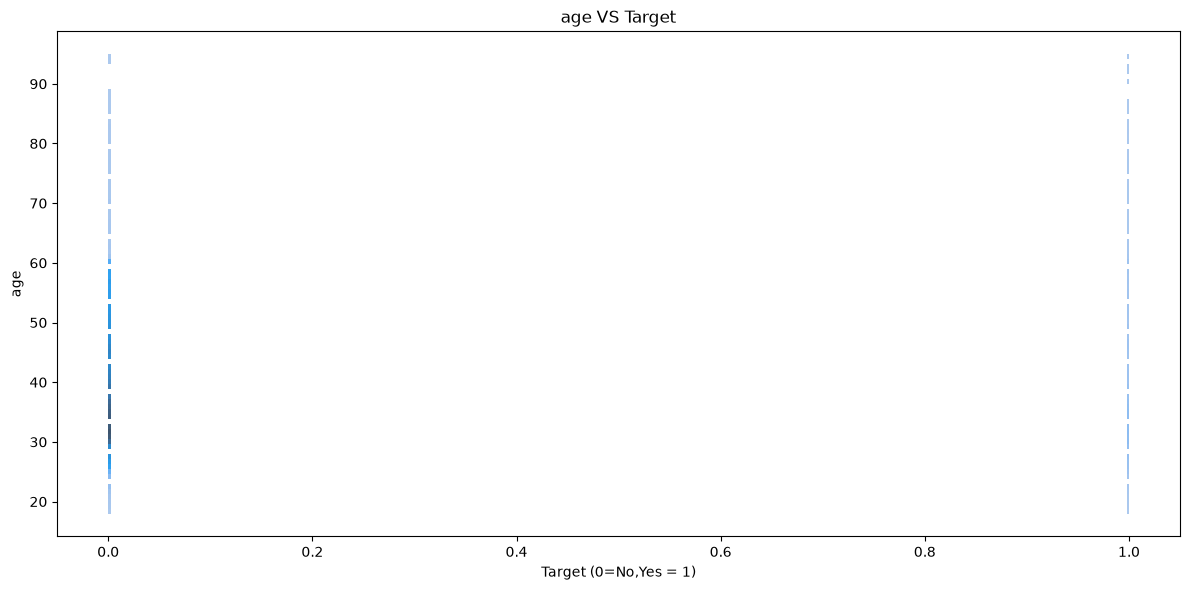

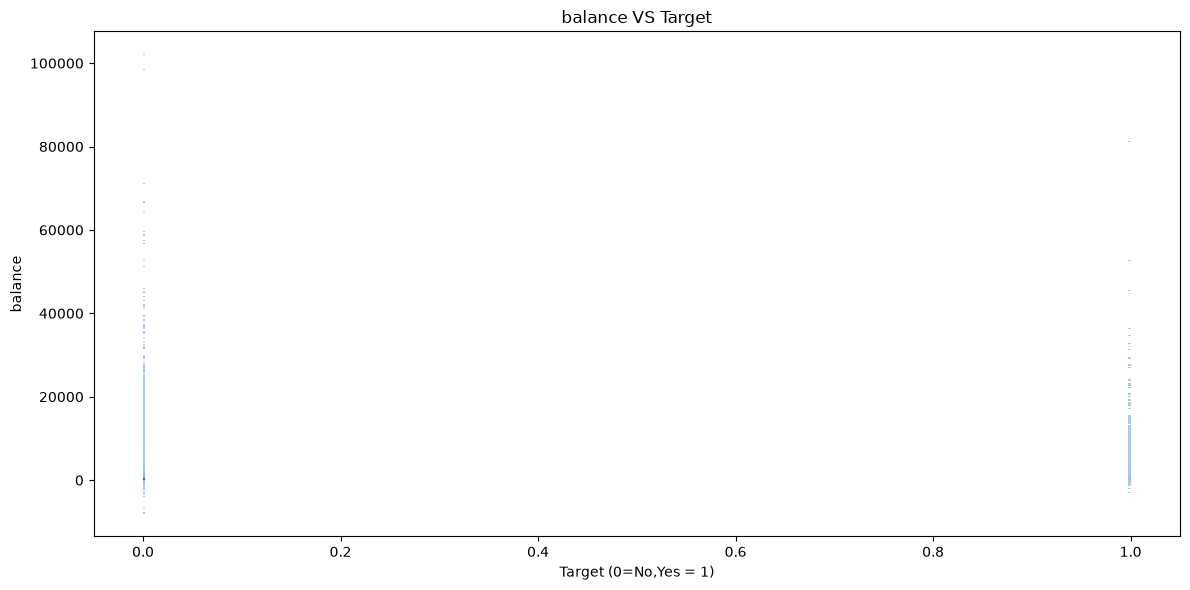

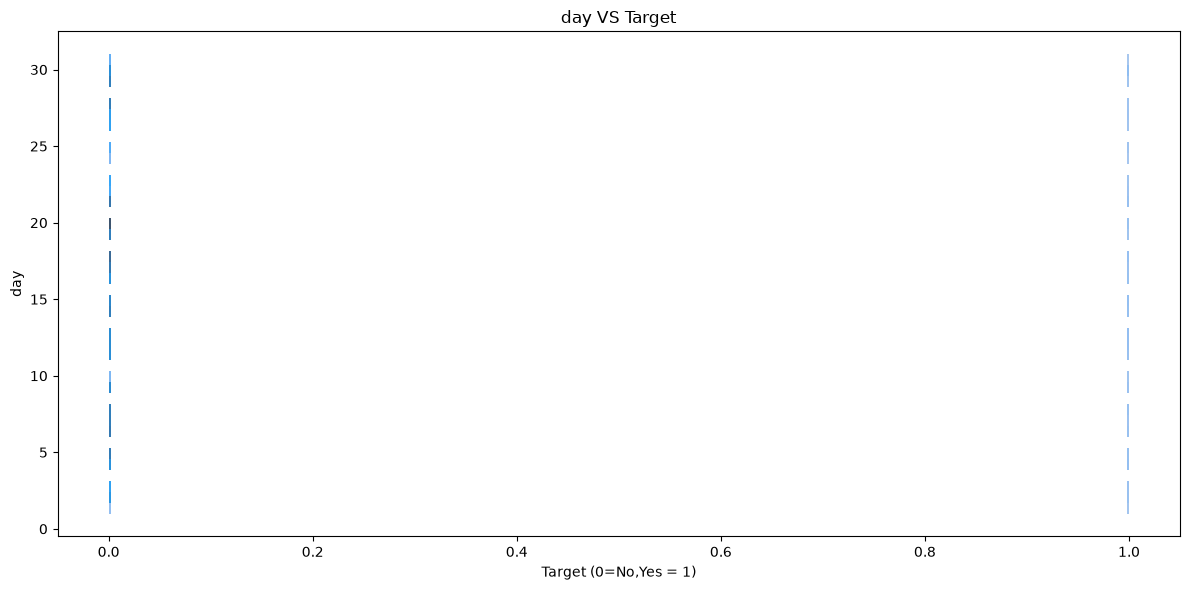

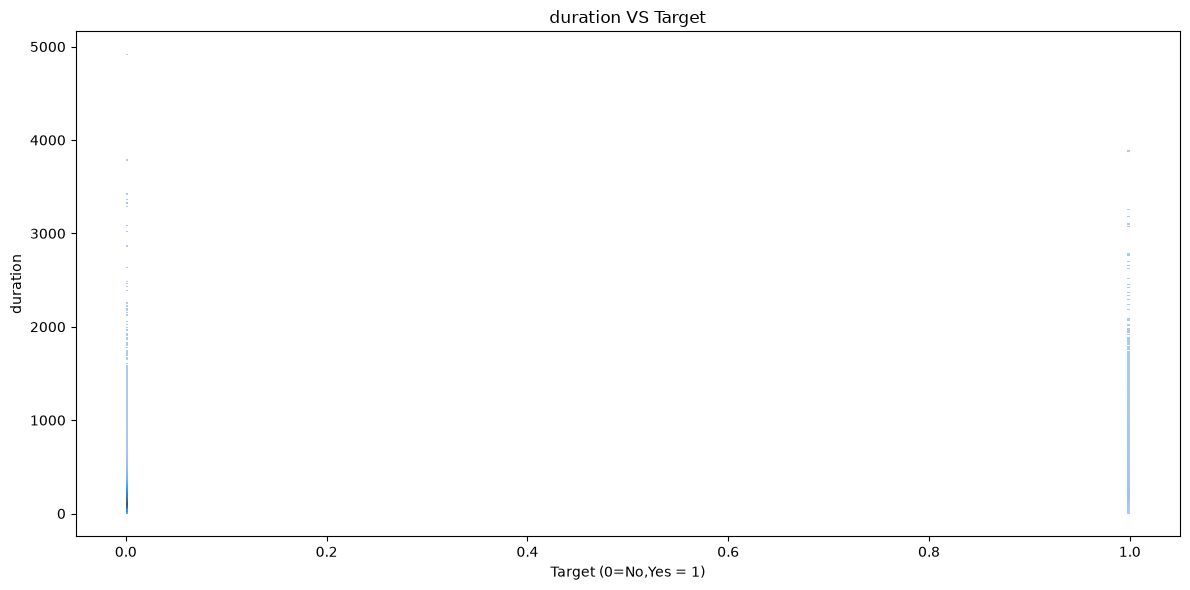

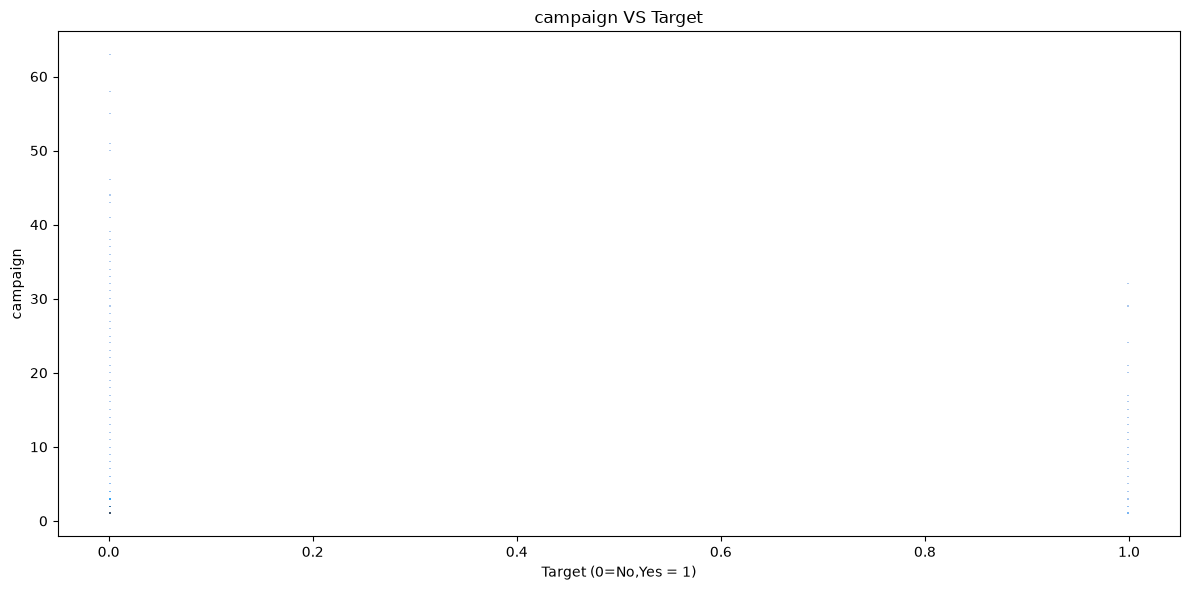

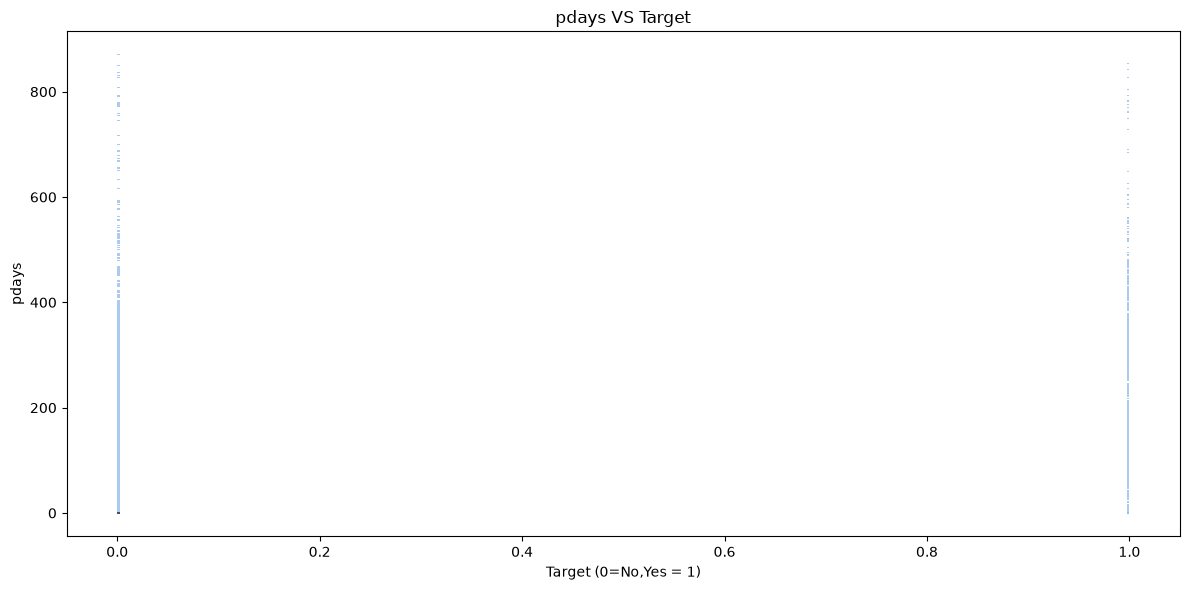

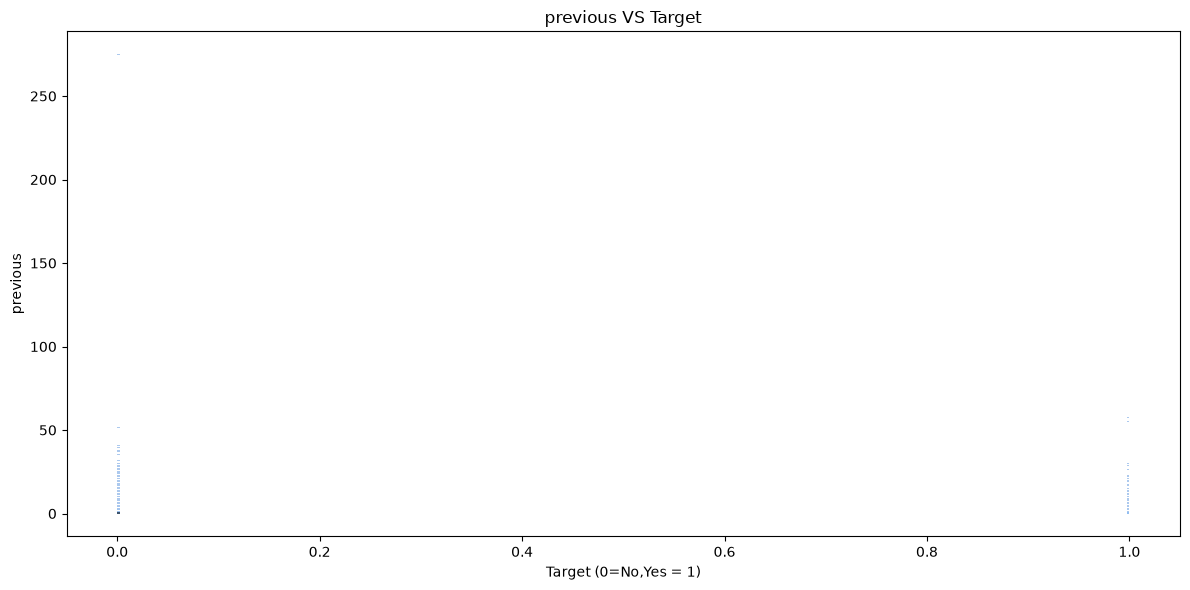

In [31]:
numerical_columns = df.select_dtypes(
    include="number"
).columns.drop("Target", errors="ignore")

for col in numerical_columns:
    plt.figure(figsize=(12, 6))
    
    sns.histplot(data=df, x="Target", y=col,kde=True)
    
    plt.title(f"{col} VS Target")
    plt.xlabel("Target (0=No,Yes = 1)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

#### Correlation analysis

In [32]:
correlation = df.select_dtypes(include="number").corr()

print(
    correlation['Target']
    .drop('Target')
    .sort_values(ascending=False)
)


duration    0.394521
pdays       0.103621
previous    0.093236
balance     0.052838
age         0.025155
day        -0.028348
campaign   -0.073172
Name: Target, dtype: float64


**Observation:** The correlation analysis shows that `duration` has the strongest positive linear association with the target (r = 0.395), followed by `pdays` (r = 0.104) and `previous` (r = 0.093). The features `balance` and `age` exhibit very weak positive correlations, while `day` and `campaign` show very weak negative correlations. Overall, none of the numerical features exhibits a strong linear relationship with the target. However, correlation alone cannot establish causation or rule out nonlinear relationships.

### Correlation heatmap

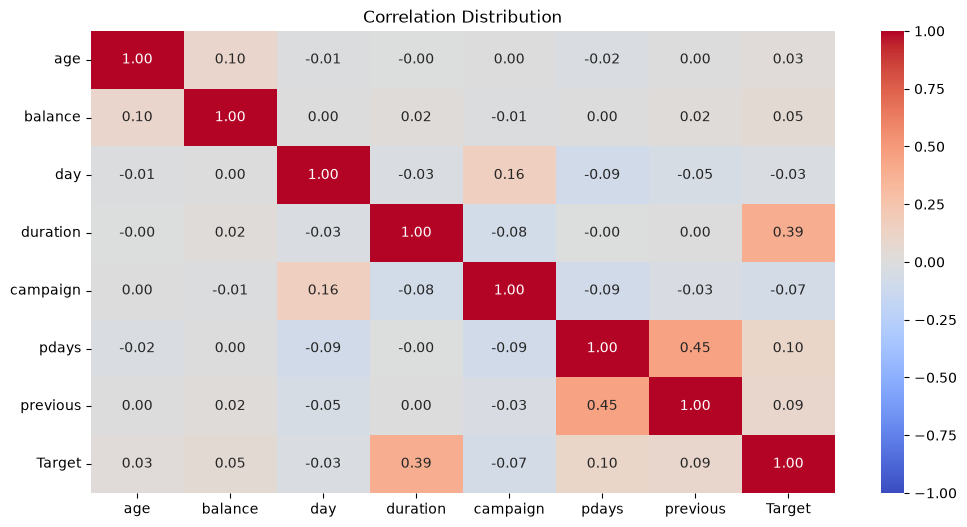

In [35]:
plt.figure(figsize=(12,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
plt.title("Correlation Distribution")
plt.show()

### Check relationships between input features

In [38]:
input_corr = df[numerical_columns].corr()
print(input_corr)

               age   balance       day  duration  campaign     pdays  previous
age       1.000000  0.097783 -0.009120 -0.004648  0.004760 -0.023758  0.001288
balance   0.097783  1.000000  0.004503  0.021560 -0.014578  0.003435  0.016674
day      -0.009120  0.004503  1.000000 -0.030206  0.162490 -0.093044 -0.051710
duration -0.004648  0.021560 -0.030206  1.000000 -0.084570 -0.001565  0.001203
campaign  0.004760 -0.014578  0.162490 -0.084570  1.000000 -0.088628 -0.032855
pdays    -0.023758  0.003435 -0.093044 -0.001565 -0.088628  1.000000  0.454820
previous  0.001288  0.016674 -0.051710  0.001203 -0.032855  0.454820  1.000000


### Outliers Detection 

In [41]:
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lowwer_bound = Q1 - 1.5 * IQR
    upper_bound  = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lowwer_bound) | (df[col] > upper_bound)]
    
    print(f"\nColumns: {col}")
    print(f"Q1 :{Q1}")
    print(f"Q3: {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower Bound :{lowwer_bound}")
    print(f"Upper bound : {upper_bound}")
    print(f"Number of Outliers :{len(outliers)}")
    print("----------------------------")


Columns: age
Q1 :33.0
Q3: 48.0
IQR: 15.0
Lower Bound :10.5
Upper bound : 70.5
Number of Outliers :487
----------------------------

Columns: balance
Q1 :72.0
Q3: 1428.0
IQR: 1356.0
Lower Bound :-1962.0
Upper bound : 3462.0
Number of Outliers :4729
----------------------------

Columns: day
Q1 :8.0
Q3: 21.0
IQR: 13.0
Lower Bound :-11.5
Upper bound : 40.5
Number of Outliers :0
----------------------------

Columns: duration
Q1 :103.0
Q3: 319.0
IQR: 216.0
Lower Bound :-221.0
Upper bound : 643.0
Number of Outliers :3235
----------------------------

Columns: campaign
Q1 :1.0
Q3: 3.0
IQR: 2.0
Lower Bound :-2.0
Upper bound : 6.0
Number of Outliers :3064
----------------------------

Columns: pdays
Q1 :-1.0
Q3: -1.0
IQR: 0.0
Lower Bound :-1.0
Upper bound : -1.0
Number of Outliers :8257
----------------------------

Columns: previous
Q1 :0.0
Q3: 0.0
IQR: 0.0
Lower Bound :0.0
Upper bound : 0.0
Number of Outliers :8257
----------------------------


#### Multicollinearity

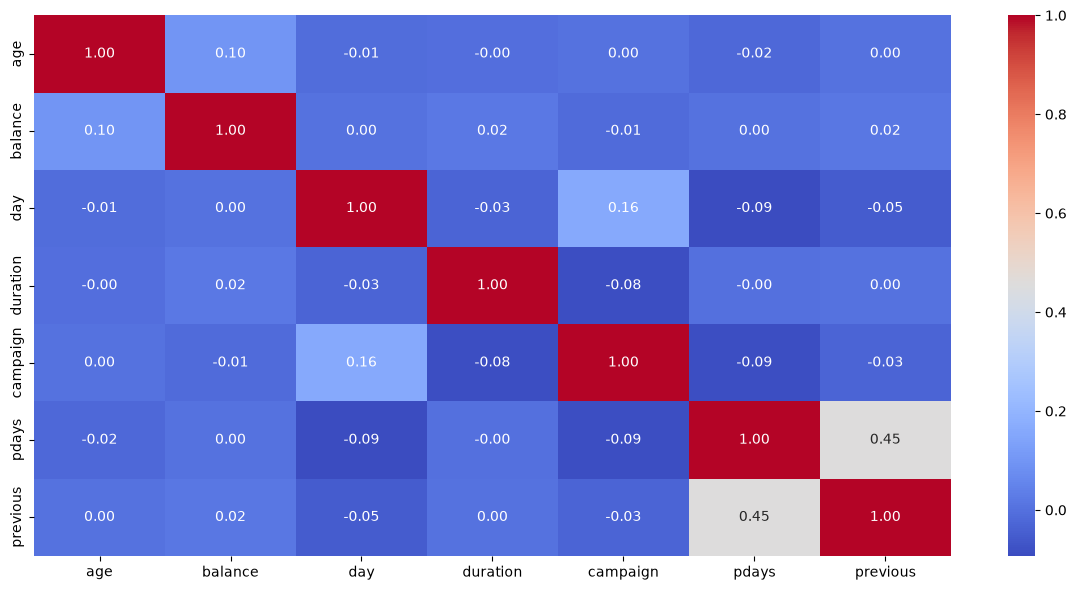

In [43]:
X = df.select_dtypes(
    include="number"
).drop(
    columns=['Target'], errors="ignore"
)

## Calculate correlation
correlations = X.corr()

# Visualize the correlation matrix
plt.figure(figsize=(12, 6))
sns.heatmap(correlations, annot=True, cmap="coolwarm", fmt=".2f")
plt.tight_layout()
plt.show()

In [44]:
correlations

,age,balance,day,duration,campaign,pdays,previous
age,1.000000,0.097783,-0.009120,-0.004648,0.004760,-0.023758,0.001288
balance,0.097783,1.000000,0.004503,0.021560,-0.014578,0.003435,0.016674
day,-0.009120,0.004503,1.000000,-0.030206,0.162490,-0.093044,-0.051710
duration,-0.004648,0.021560,-0.030206,1.000000,-0.084570,-0.001565,0.001203
campaign,0.004760,-0.014578,0.162490,-0.084570,1.000000,-0.088628,-0.032855
pdays,-0.023758,0.003435,-0.093044,-0.001565,-0.088628,1.000000,0.454820
previous,0.001288,0.016674,-0.051710,0.001203,-0.032855,0.454820,1.000000


In [46]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical input features
X = df.select_dtypes(include="number").drop(
    columns=["Target"], errors="ignore"
).copy()

# Remove rows with missing or infinite values
import numpy as np

X = X.replace([np.inf, -np.inf], np.nan).dropna()

# Calculate VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values("VIF", ascending=False))

    Feature       VIF
5     pdays  1.276189
6  previous  1.261640
4  campaign  1.040116
2       day  1.034433
1   balance  1.010681
0       age  1.010613
3  duration  1.008075


Observation – Multicollinearity Analysis (VIF)

The VIF analysis shows that all numerical input features have VIF values close to 1, ranging from 1.008 to 1.276. The highest VIF is observed for `pdays` (1.276), followed by `previous` (1.262). These values are well below the commonly used threshold of 5, indicating that multicollinearity among the numerical features is very low. Therefore, no numerical feature needs to be removed based on VIF alone.

#### Leakage check

In [47]:
# Separate input features and target
X = df.drop(columns=["Target"])
y = df["Target"]

# Check whether target is accidentally included in X
print("Target in X:", "Target" in X.columns)

print("\nInput features:")
print(X.columns.tolist())

Target in X: False

Input features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']


### Check target and input features

In [52]:
# Separate input features and target
X = df.drop(columns=["Target"])
y = df["Target"]

# Check whether target is accidentally included in X
print("Target in X:", "Target" in X.columns)

print("\nInput features:")
print(X.columns.tolist())

Target in X: False

Input features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']


### Check suspicious features

In [51]:
# Review features that may not be available at prediction time
suspicious_features = ["duration"]

for col in suspicious_features:
    if col in X.columns:
        print(f"{col}: Present in input features")
    else:
        print(f"{col}: Not present in input features")

duration: Not present in input features


In [53]:
X = df.drop(columns=["Target", "duration"], errors="ignore")
y = df["Target"]

#### . Check train-test split order

In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36168, 15)
Testing data: (9043, 15)


Observation: These checks help identify common leakage risks, but no single code snippet can automatically detect every type of data leakage. You must also verify that each feature would genuinely be available when your model makes its prediction.